In [1]:
!nvidia-smi

Mon Oct 12 05:28:37 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   39C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [3]:
!pip install ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 3.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 42.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.5/96.5 kB 12.1 MB/s eta 0:00:00


In [4]:
from ultralytics import YOLO

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


In [5]:
import ultralytics
ultralytics.checks()

Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 42.4/112.6 GB disk)


In [6]:
!pip install roboflow

from roboflow import Roboflow
rf = Roboflow(api_key="nJBC3Kr2Z6qyZZJgYERo")
project = rf.workspace("saikat-gsu12").project("bangla-sign-language-xisdi")
version = project.version(5)
dataset = version.download("yolo26")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 373.9/373.9 kB 12.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 98.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.4/58.4 kB 7.5 MB/s eta 0:00:00
  Attempting uninstall: typer
    Found existing installation: typer 0.27.2
    Uninstalling typer-0.27.2:
      Successfully uninstalled typer-0.27.2
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to Bangla-Sign-Language-5 in yolo26:: 100%|██████████| 11401/11401 [00:02<00:00, 5334.86it/s] 


In [7]:
# Load a model
model = YOLO("yolo26n.pt")  # load a pretrained model

# Train the model
results = model.train(data="/content/Bangla-Sign-Language-5/data.yaml", epochs=20, imgsz=640)

Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/Bangla-Sign-Language-5/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train, nbs=64, nms=None, opset=None, optimize=Fa

In [8]:
from IPython.display import Image

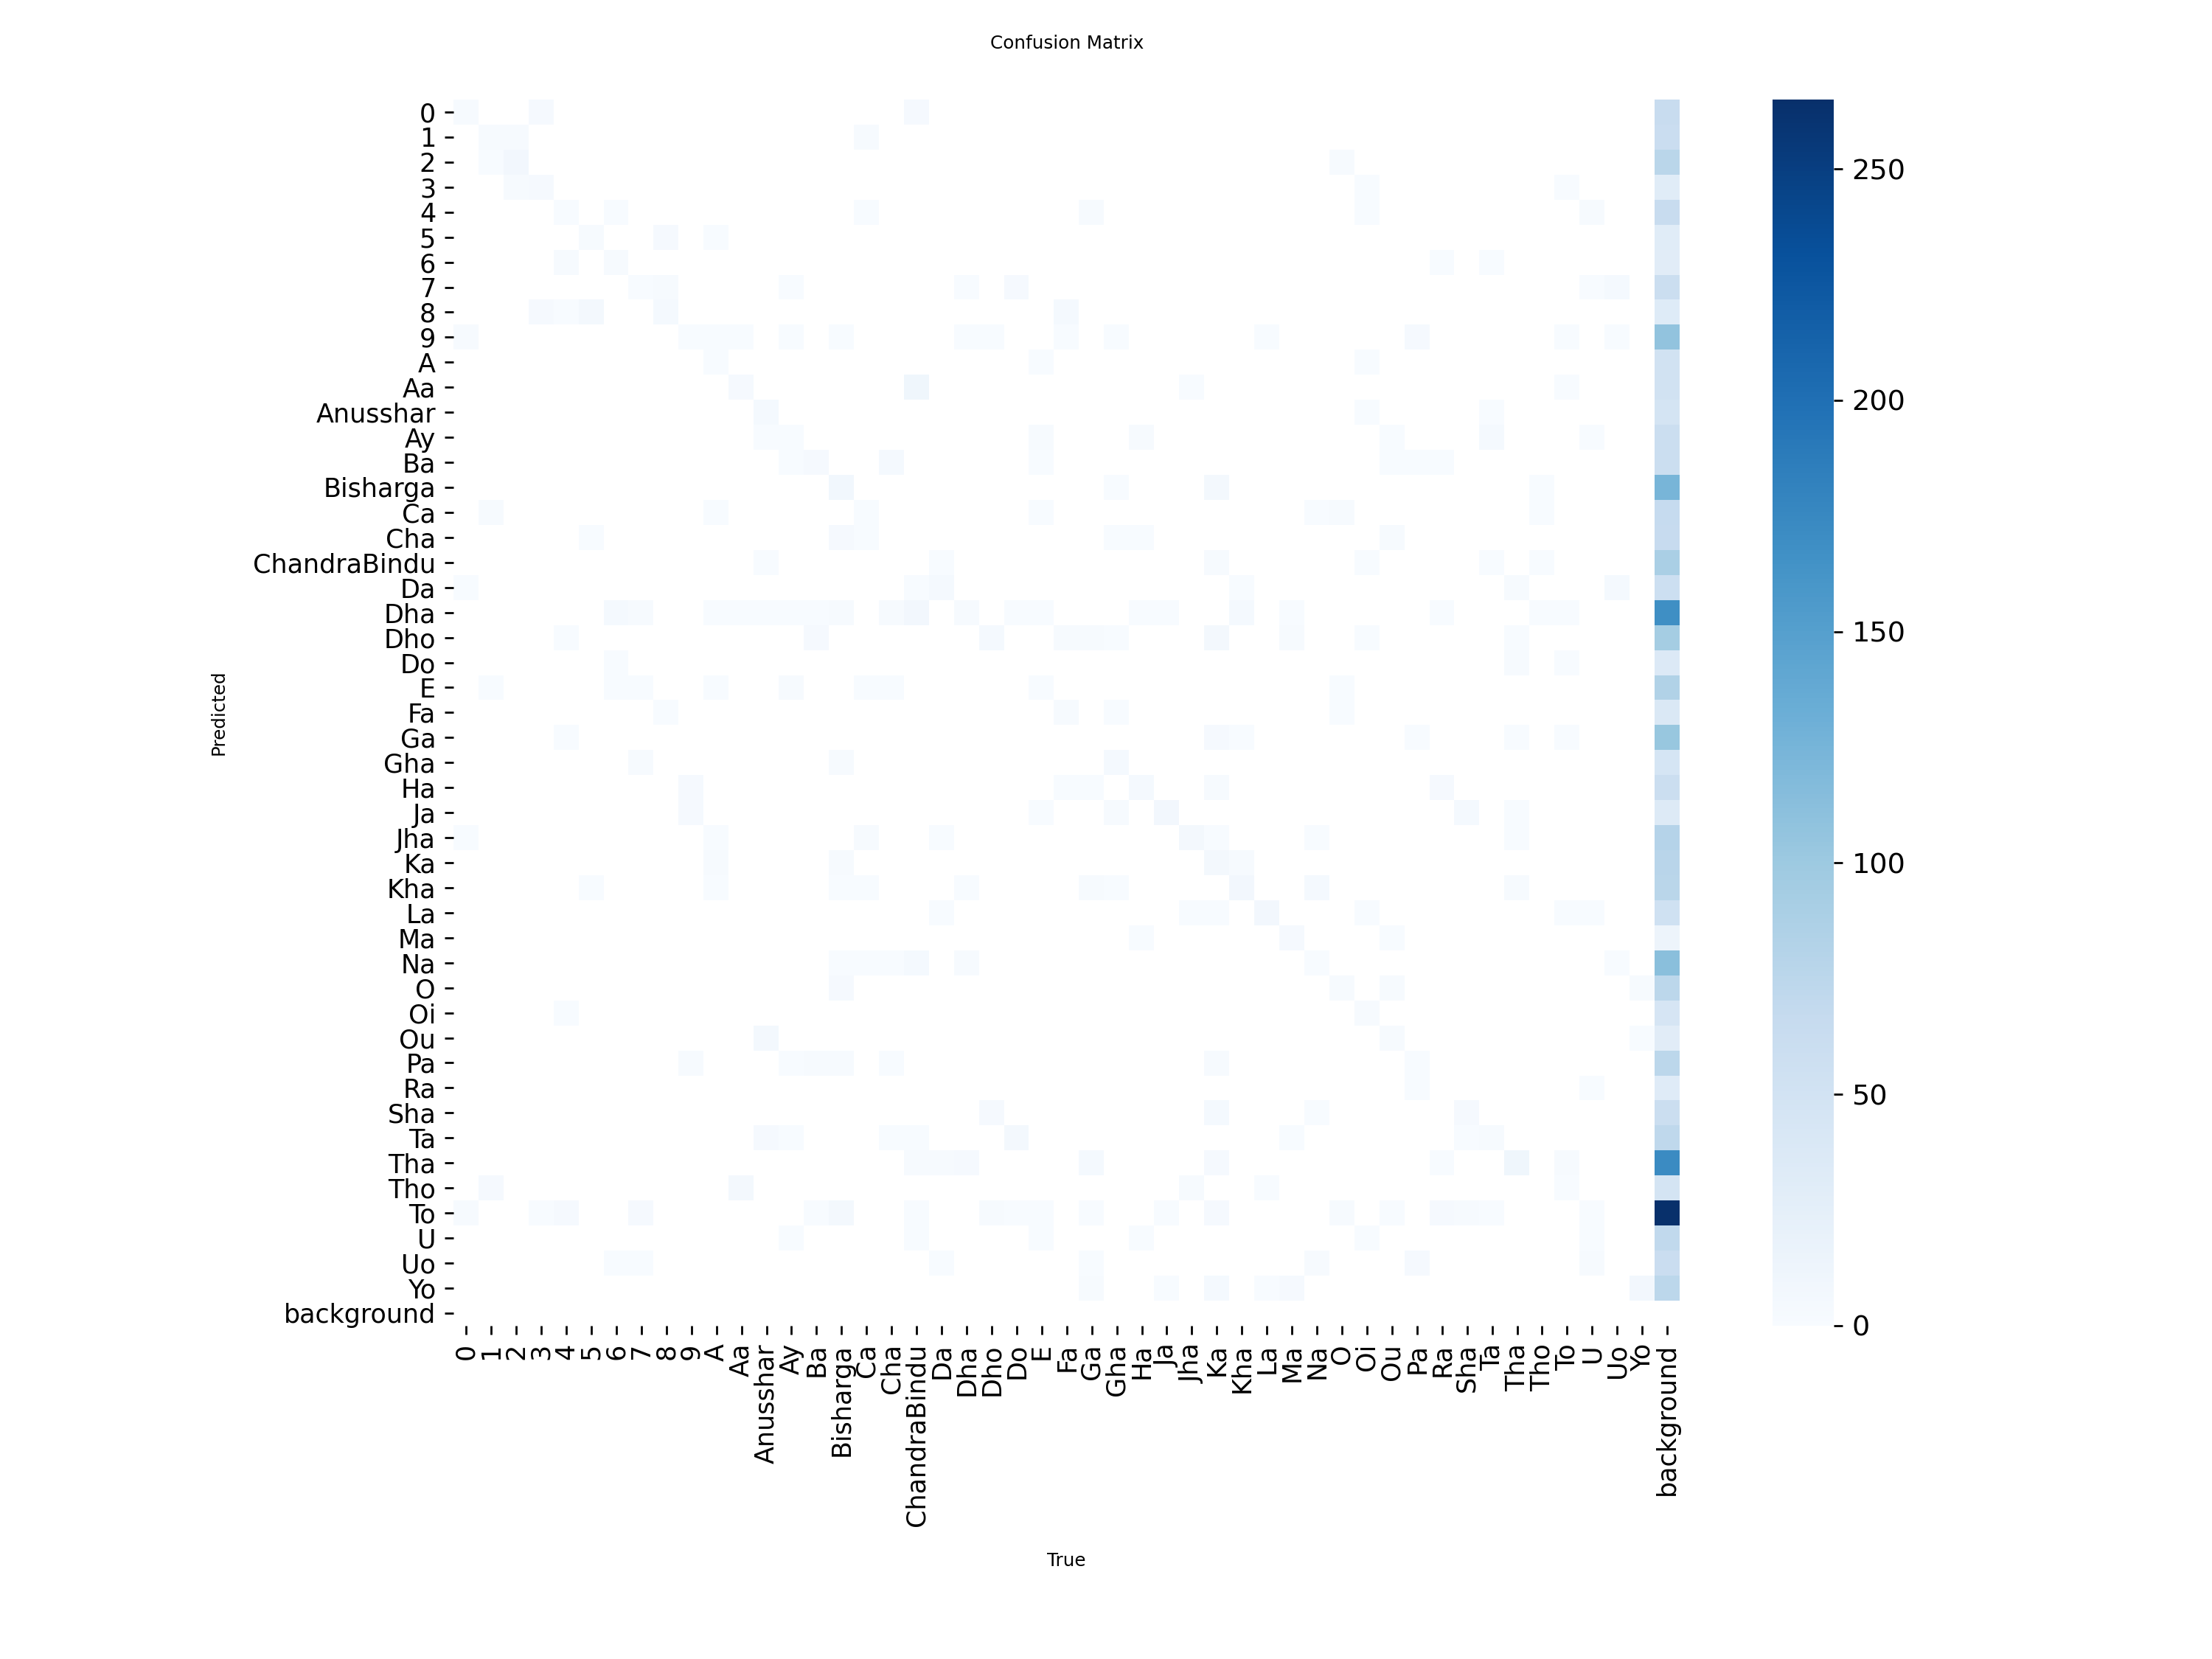

In [17]:
Image("/content/runs/detect/val/confusion_matrix.png", width=600)

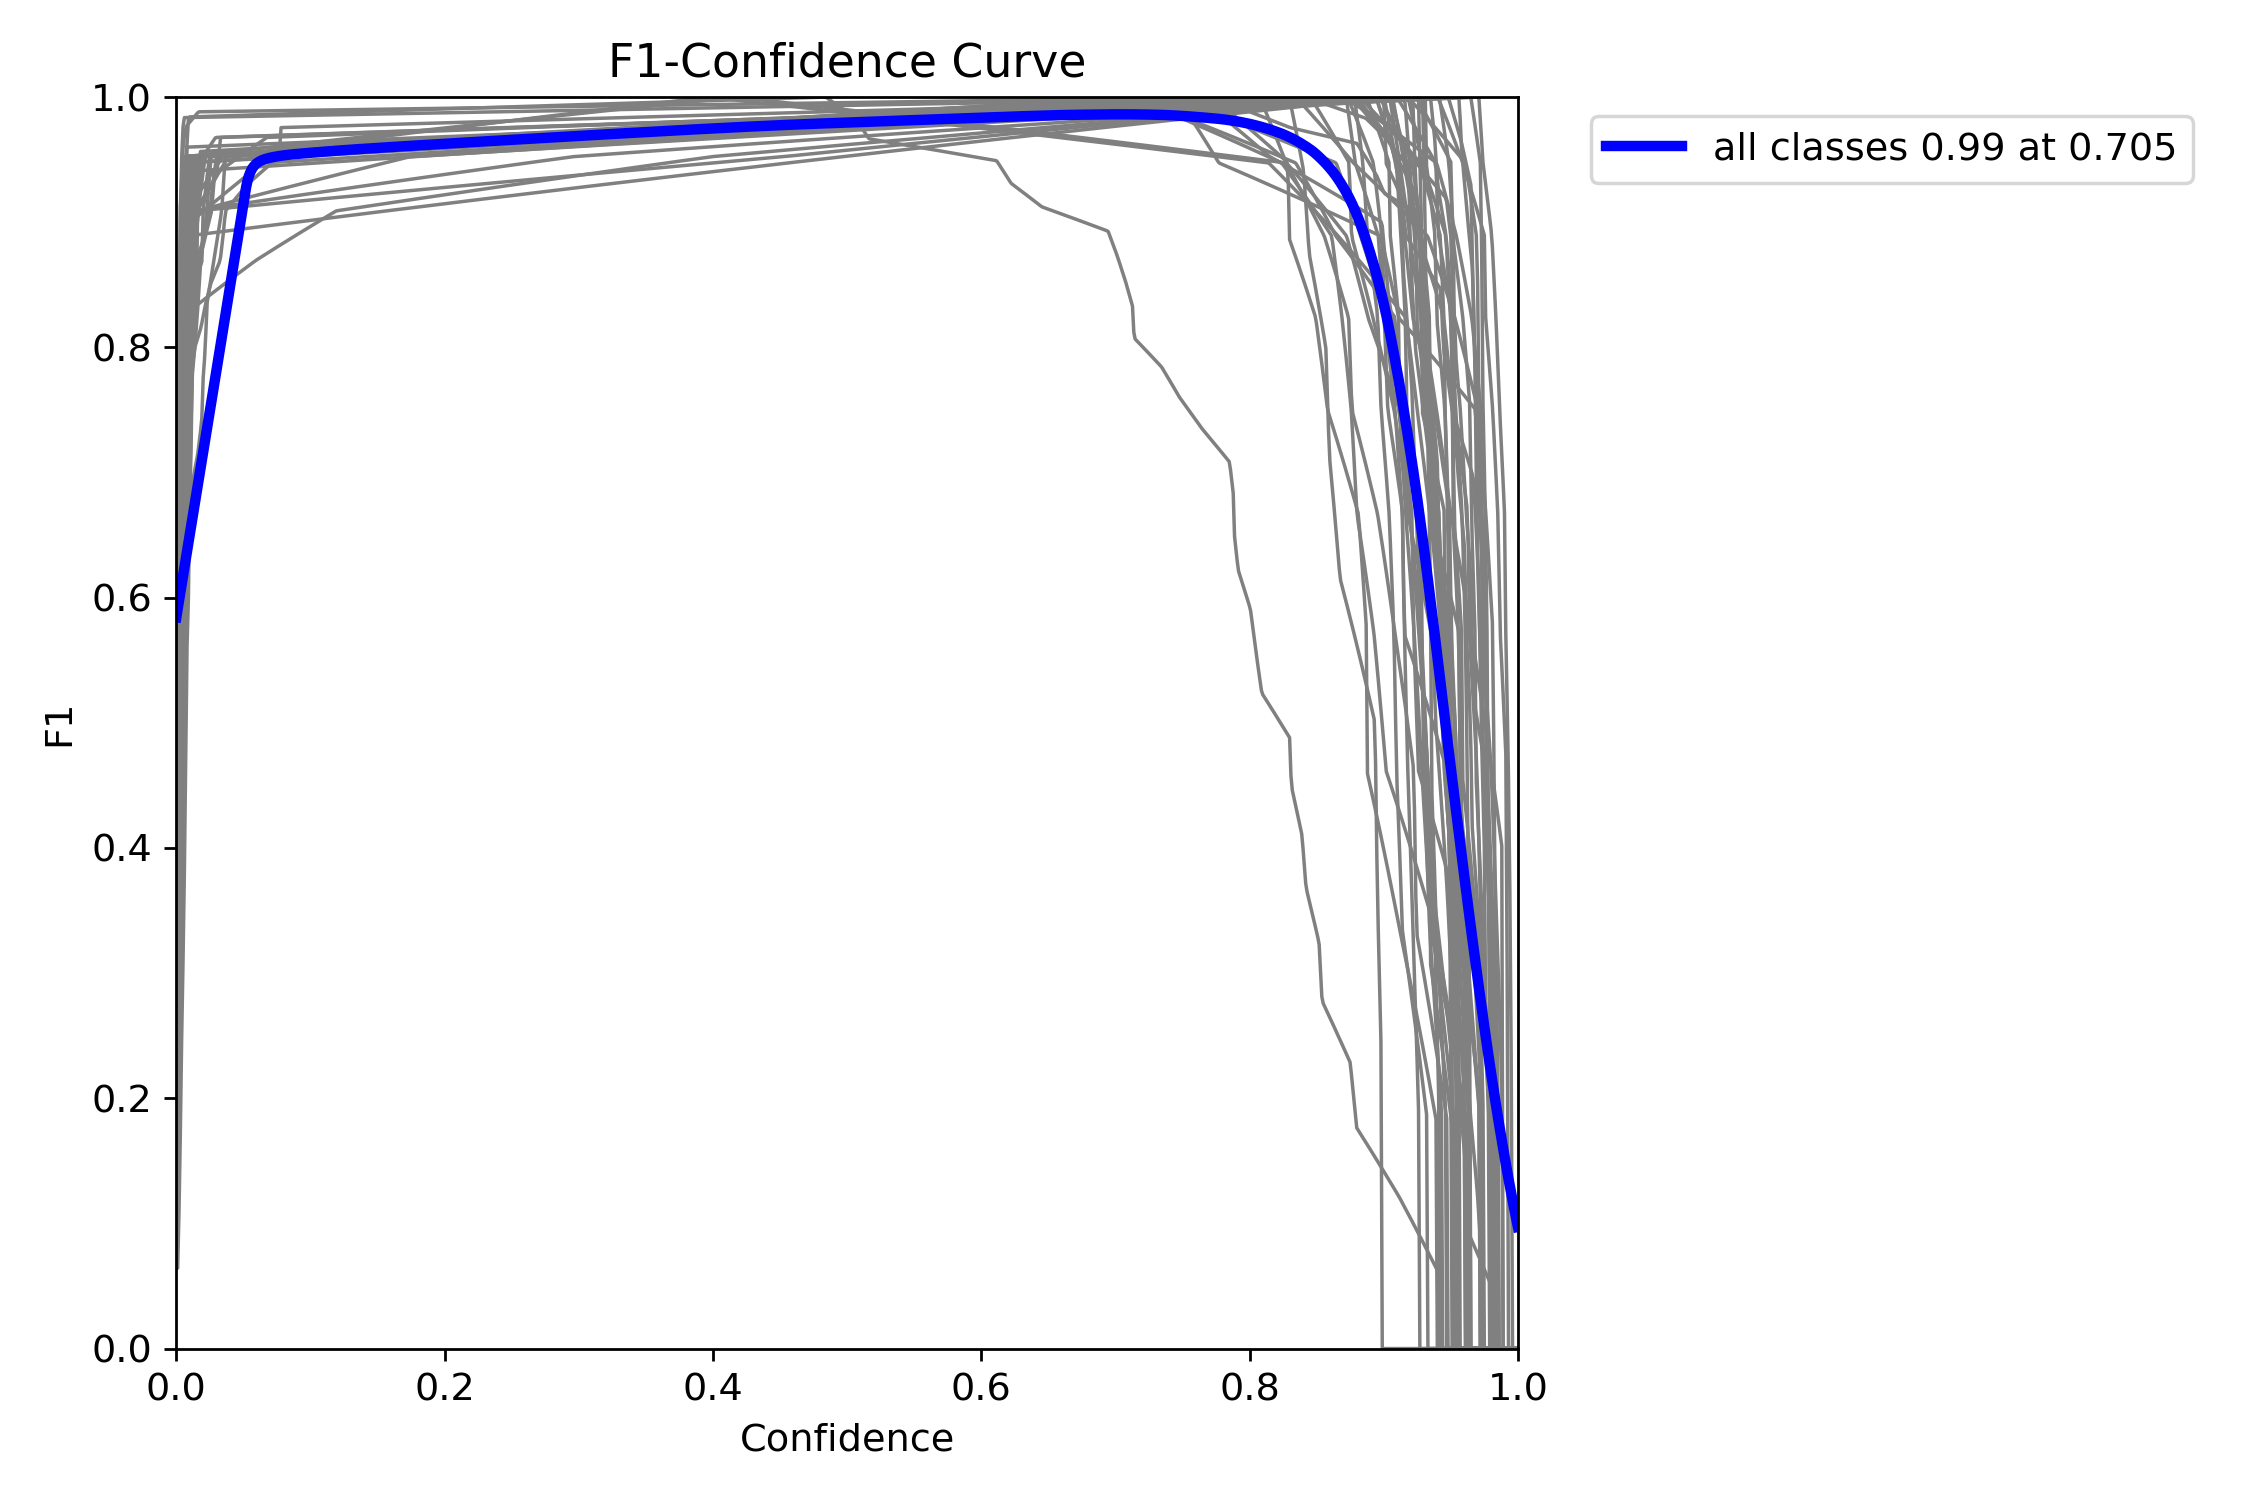

In [41]:
Image("/content/runs/detect/val/BoxF1_curve.png", width=600)

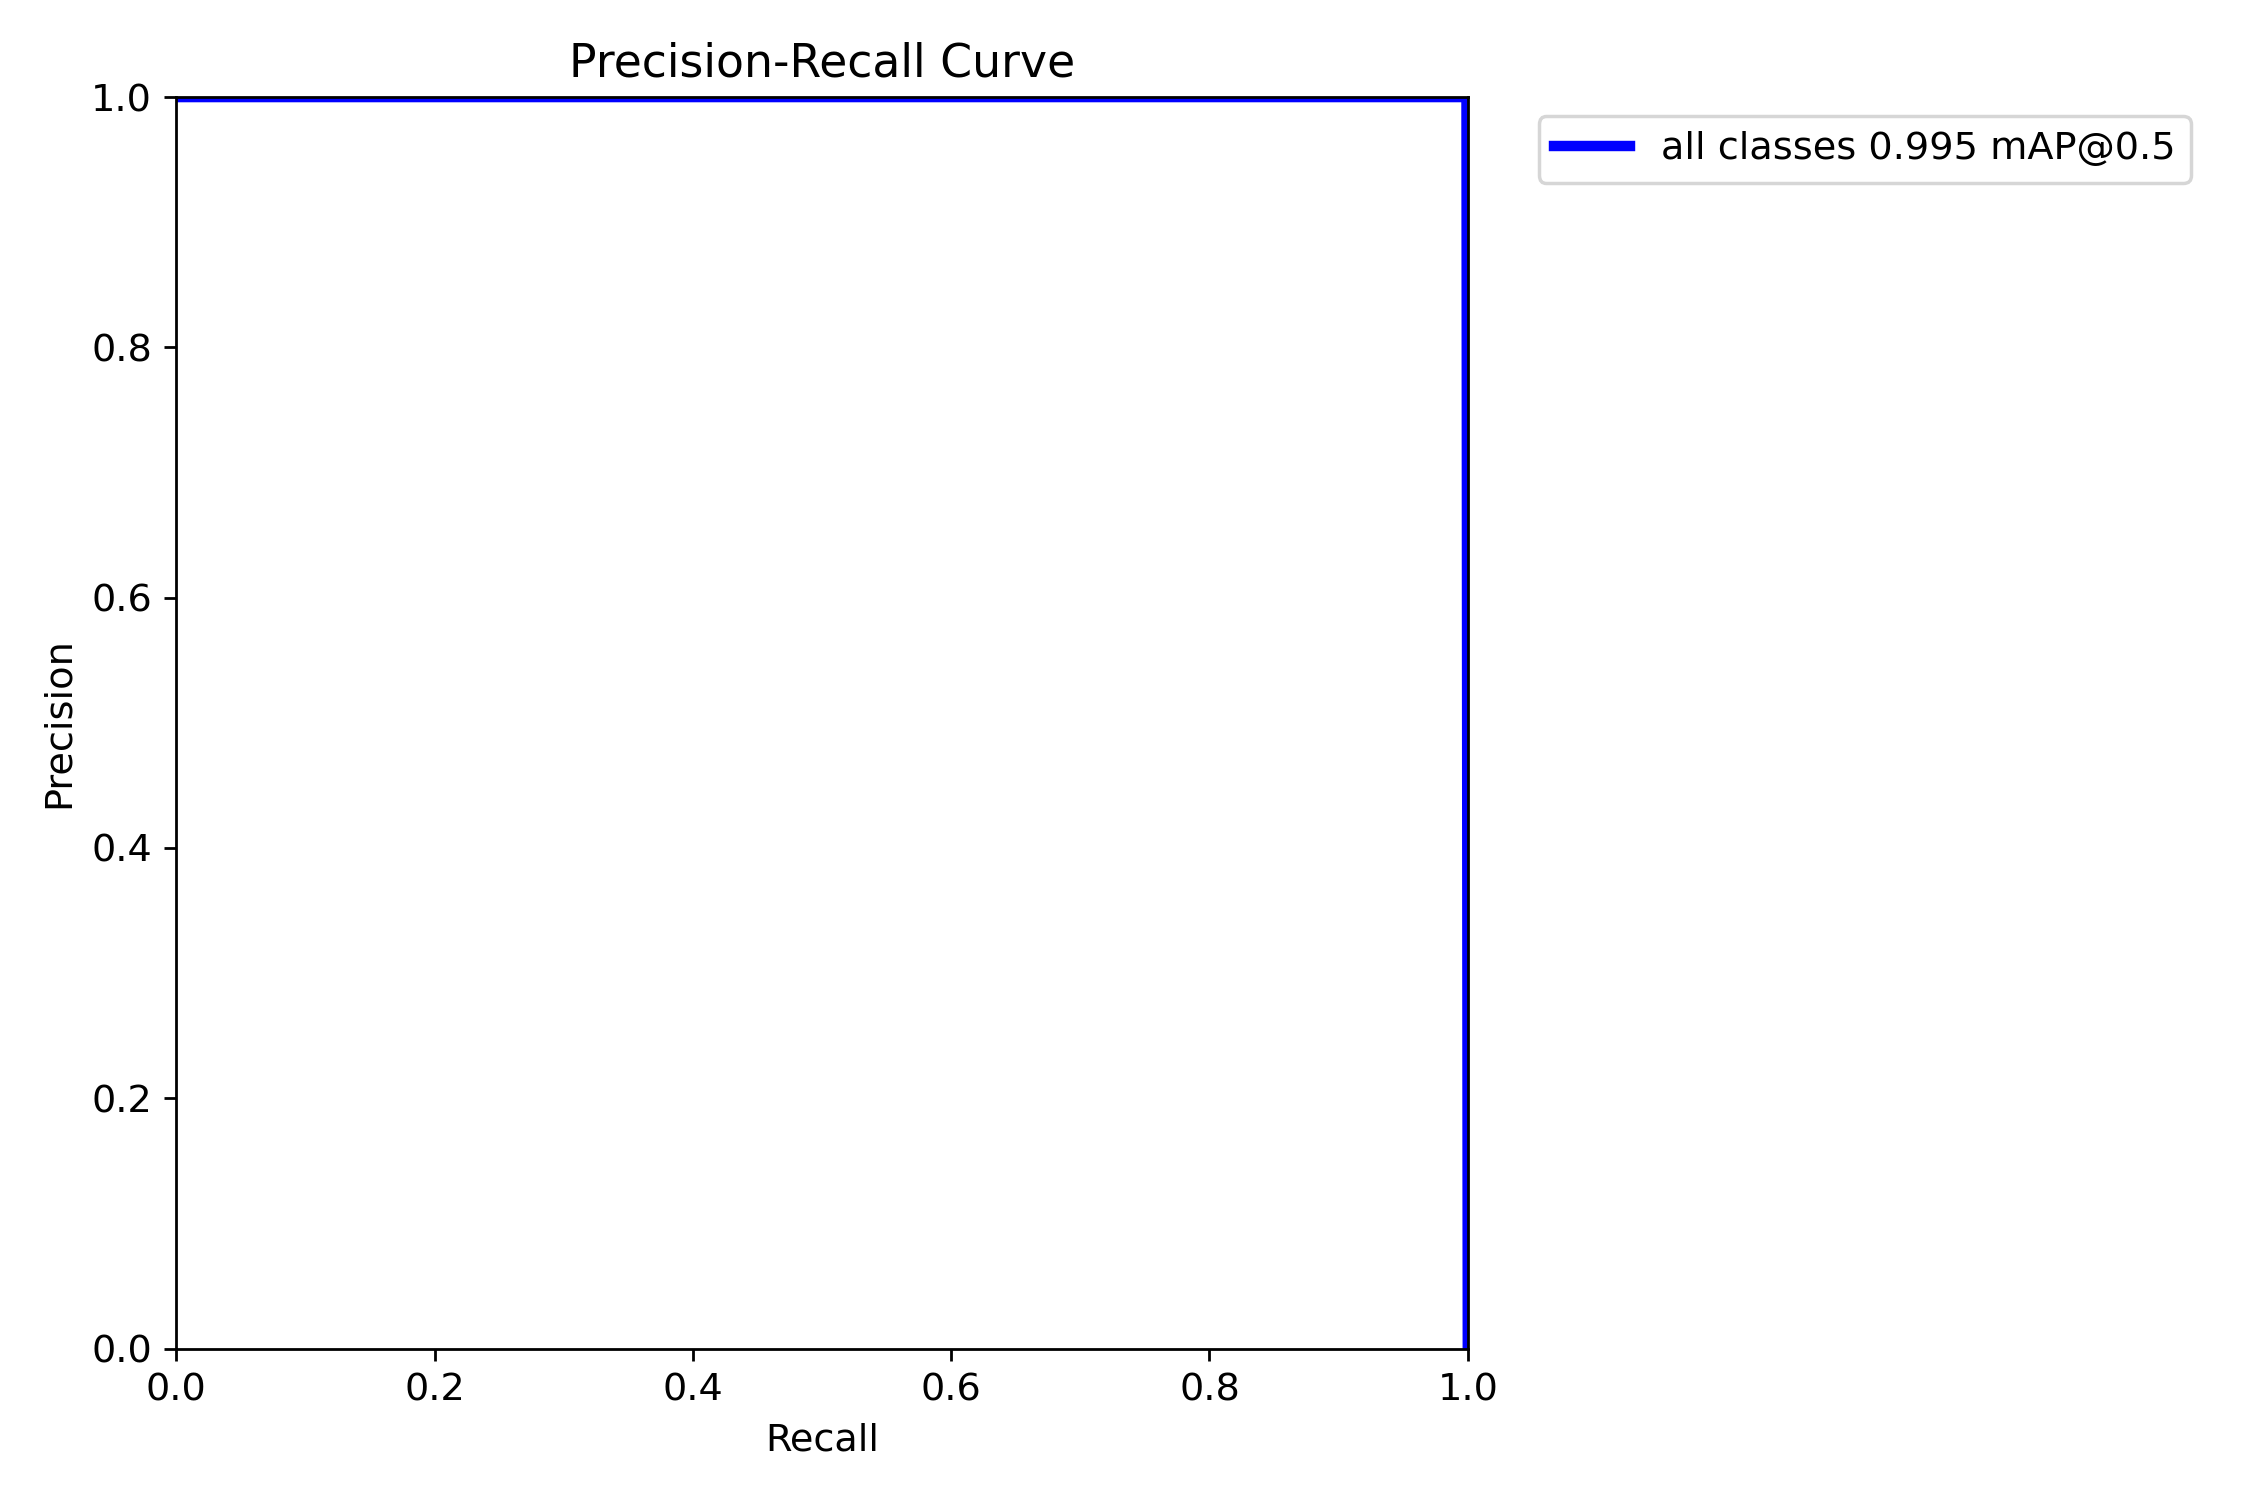

In [42]:
Image("/content/runs/detect/val/BoxPR_curve.png", width=600)

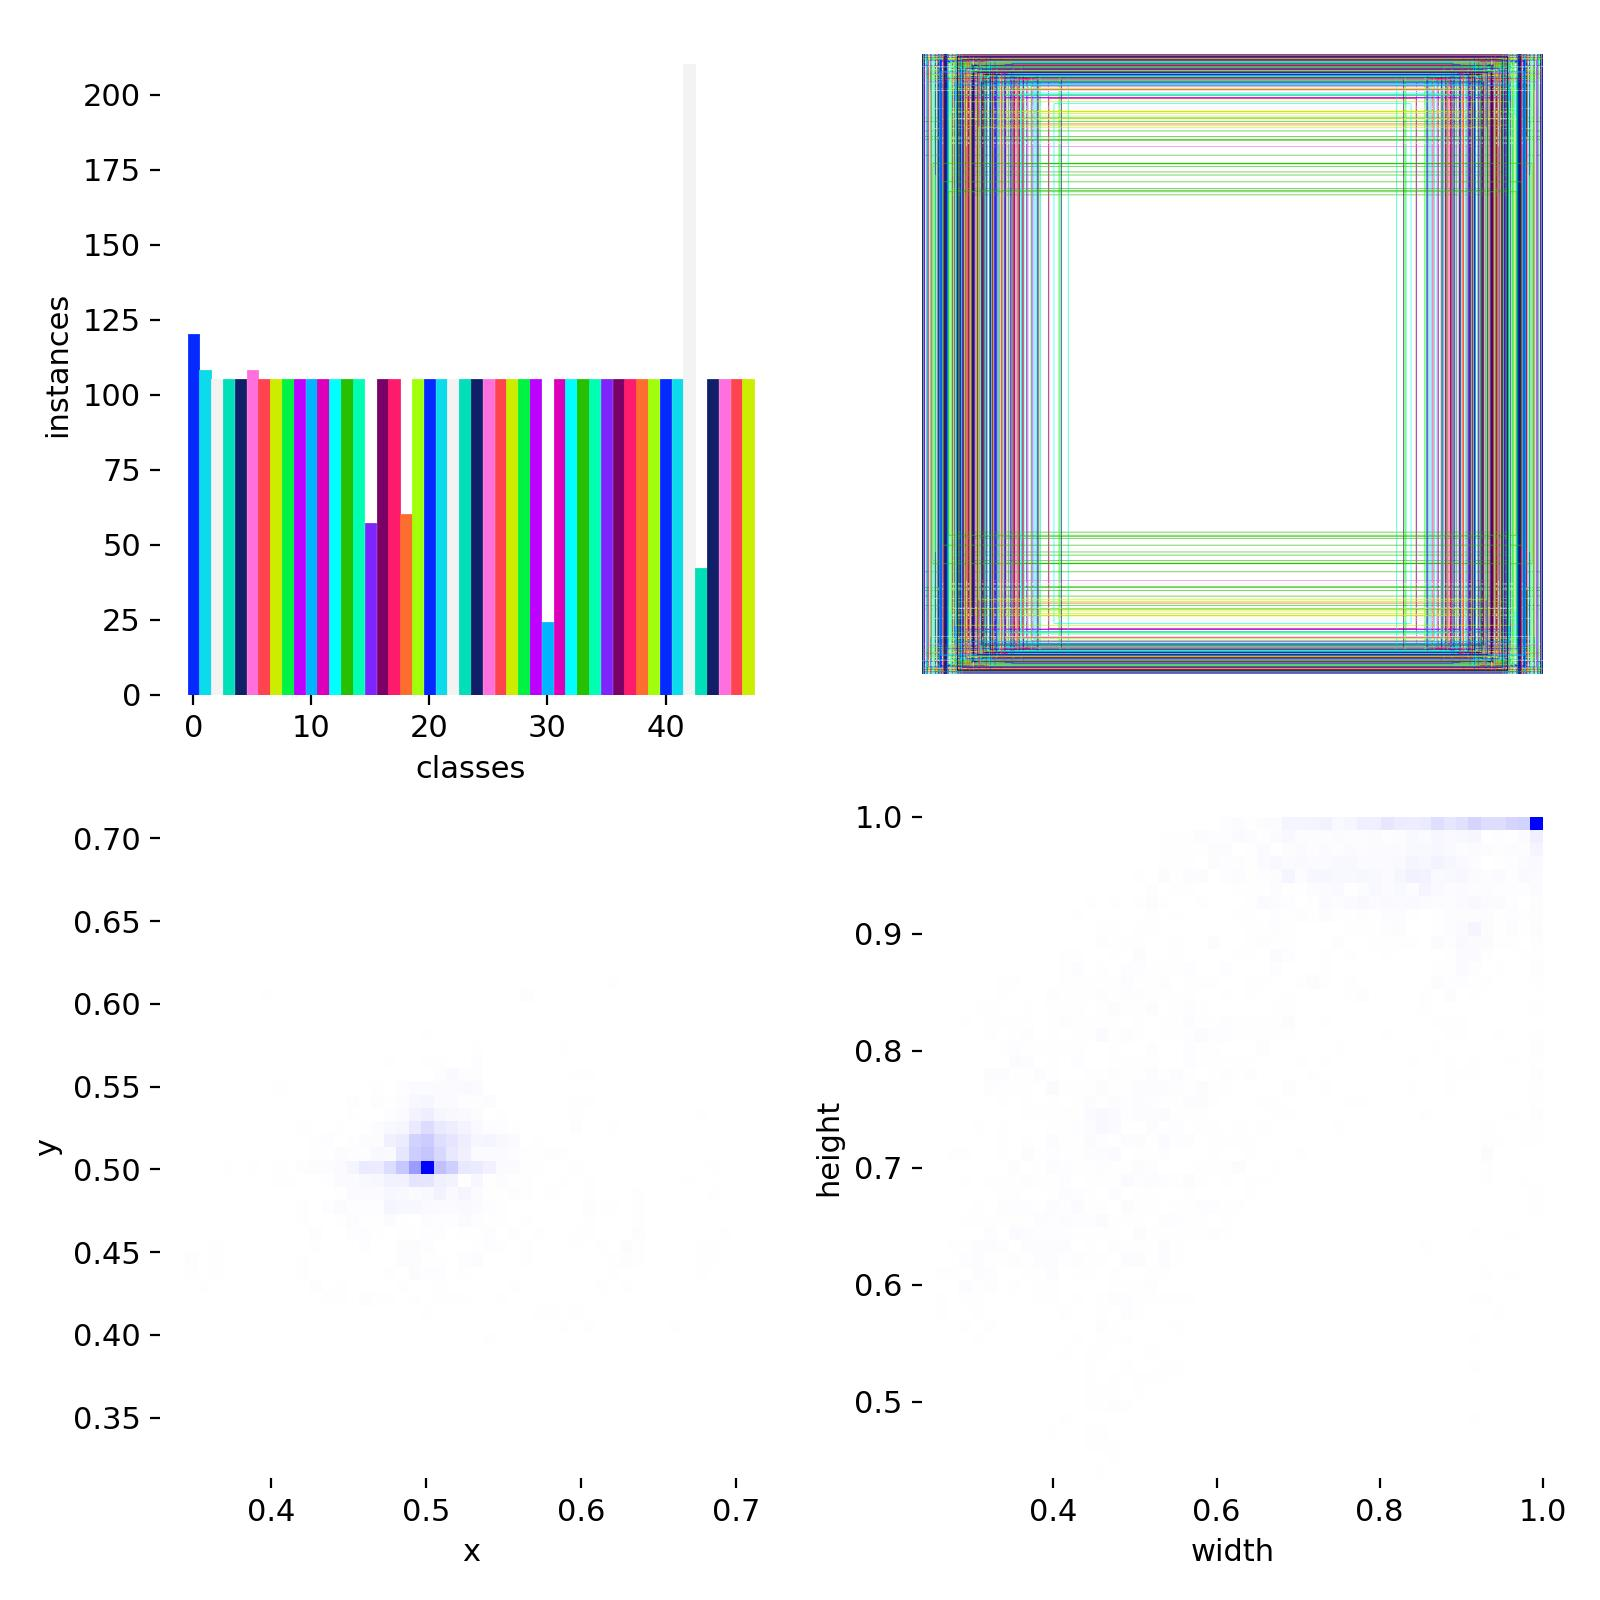

In [13]:
Image("/content/runs/detect/train/labels.jpg", width=600)

In [14]:
from ultralytics import YOLO

# Load a model
model = YOLO("/content/runs/detect/train/weights/best.pt")  # load a custom model

# Validate the model
metrics = model.val()  # no arguments needed, dataset and settings remembered
metrics.box.map  # map50-95
metrics.box.map50  # map50
metrics.box.map75  # map75
metrics.box.maps  # a list contains map50-95 of each category

Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 121 layers, 2,401,156 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1818.6±680.1 MB/s, size: 51.3 KB)
val: Scanning /content/Bangla-Sign-Language-5/valid/labels.cache... 570 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 570/570 159.4Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 36/36 5.0it/s 7.2s
                   all        570        570      0.983      0.992      0.995      0.888
                     0          8          8      0.975          1      0.995      0.907
                     1          9          9      0.976          1      0.995      0.848
                     2         11         11      0.994          1      0.995      0.824
                     3         10         10      0.988          1      0.995      0.868
                     4       

array([    0.90663,     0.84783,     0.82359,     0.86816,      0.7759,       0.892,      0.8104,     0.95214,      0.8654,     0.87967,     0.83537,     0.78646,     0.90697,      0.8337,     0.91598,     0.82573,     0.92867,     0.82283,     0.92195,      0.9535,     0.92467,        0.96,       0.935,      0.8346,
           0.93892,     0.93048,      0.9535,     0.84584,     0.96722,     0.91833,     0.81551,      0.9172,     0.93567,     0.92025,     0.89133,     0.80175,     0.84641,     0.88538,     0.93567,     0.89925,       0.939,     0.90525,     0.89069,     0.90162,     0.93833,     0.81194,     0.88156,     0.94243])


image 1/1 /content/Bangla-Sign-Language-5/test/images/0414ab92e3e3b3ad93d2d68662f64e1955c4954e_jpg.rf.3afa375b9cc1f09e99709d75d89895df.jpg: 640x640 1 Ta, 10.2ms
Speed: 0.9ms preprocess, 10.2ms inference, 1.4ms postprocess per image at shape (1, 3, 640, 640)


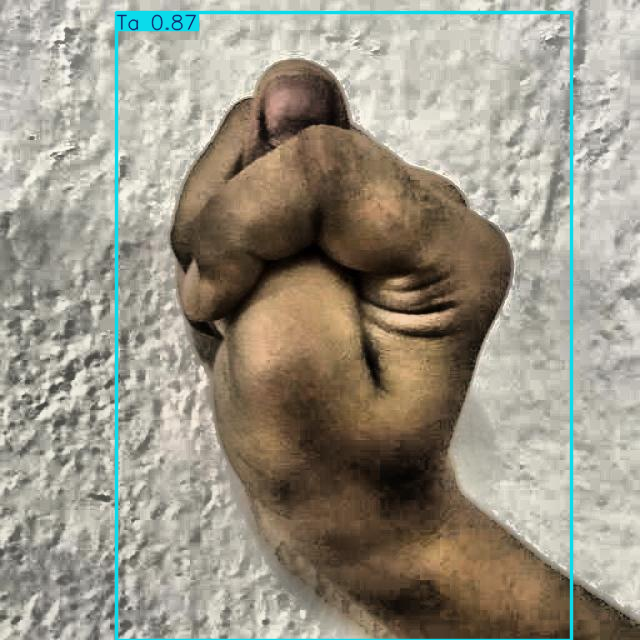

In [15]:
from ultralytics import YOLO

# Load a model
model = YOLO("/content/runs/detect/train/weights/best.pt")  # load a custom model

# Predict with the model
results = model("/content/Bangla-Sign-Language-5/test/images/0414ab92e3e3b3ad93d2d68662f64e1955c4954e_jpg.rf.3afa375b9cc1f09e99709d75d89895df.jpg")  # predict on an image

results[0].show()


image 1/1 /content/Bangla-Sign-Language-5/test/images/1e7ce53d3b32591e5dadac9a305d9bf8e3923c06_jpg.rf.696aa346900a495fc654a87d1a906735.jpg: 640x640 1 Tha, 11.5ms
Speed: 1.2ms preprocess, 11.5ms inference, 1.5ms postprocess per image at shape (1, 3, 640, 640)


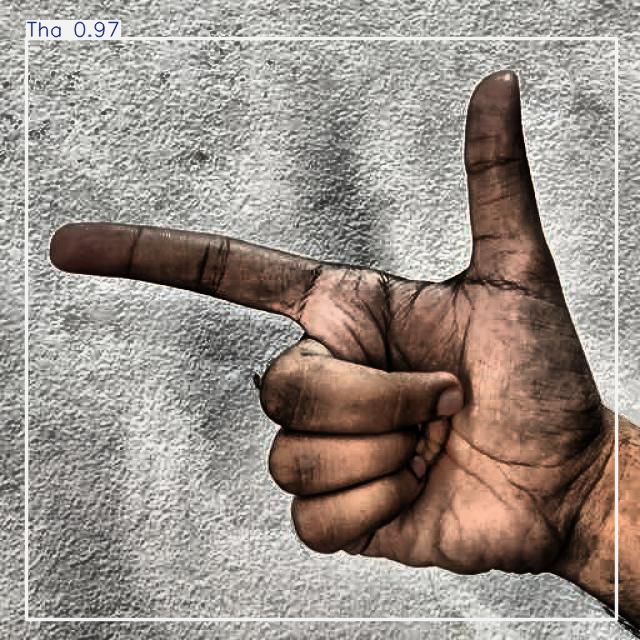

In [16]:
results = model("/content/Bangla-Sign-Language-5/test/images/1e7ce53d3b32591e5dadac9a305d9bf8e3923c06_jpg.rf.696aa346900a495fc654a87d1a906735.jpg")  # predict on an image

results[0].show()